> Experiments with [xsa.util](../trapallada/xsa/util.py)  module

In [1]:
import pathlib
import os
import tempfile
import itertools
import re

import pandas as pd
import numpy as np

from astropy.io import fits

from IPython.display import display, Markdown

import trapallada.xsa.access
import trapallada.xsa.util
import trapallada.plot

So that the notebook is aware of modifications in the the `import`ed modules

In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


The directory with the data

In [3]:
# data_dir = pathlib.Path.cwd().parent / 'data' / 'mini_rate'
# display(data_dir)
# assert data_dir.exists()

# `extract_filter_tar`

Downloading an observation...

In [4]:
sample_obs = '0404720301'
with tempfile.TemporaryDirectory(delete=False) as tmp_dir:

    # context's descriptor is turned into a `Pathlib`
    tmp_dir_root = pathlib.Path(tmp_dir)

    tar_file = trapallada.xsa.access.download_obs(sample_obs, output_directory=tmp_dir_root)

INFO: https://nxsa.esac.esa.int/nxsa-sl/servlet/data-action-aio?obsno=0404720301&level=PPS&instname=PN [astroquery.esa.xmm_newton.core]
INFO: Wrote https://nxsa.esac.esa.int/nxsa-sl/servlet/data-action-aio?obsno=0404720301&level=PPS&instname=PN to /tmp/tmp_pbfcmtf/0404720301.tar [astroquery.esa.xmm_newton.core]


...that is afterwards extracted

In [5]:
sample_obs_dir = trapallada.xsa.util.extract_filter_tar(tar_file)
sample_obs_dir

PosixPath('/tmp/tmp_pbfcmtf/0404720301')

Notice that only files whose name matches the regular expression below are kept.

In [6]:
trapallada.xsa.util.re_filename

re.compile(r'^P(\d{10})PN(X\d{3})(SRCTSR)([0-9A-F]+)\.\w+$', re.UNICODE)

Then, e.g.,

In [7]:
trapallada.xsa.util.re_filename.match('P0006010301PNS003SRSPEC0007.FTZ')

is kept but not

In [8]:
trapallada.xsa.util.re_filename.match('XMM_OM_0760_0001_NIXTMS.FIT')

In [9]:
tmp_dir_root

PosixPath('/tmp/tmp_pbfcmtf')

# `download_extract_filter`

Downloading, extracting, filtering using a single function (data used in Javi's paper)

In [10]:
obs = '0605950101' # Javi's paper
obs_dir = trapallada.xsa.util.download_extract_filter(obs, output_directory=tmp_dir_root)

INFO: https://nxsa.esac.esa.int/nxsa-sl/servlet/data-action-aio?obsno=0605950101&level=PPS&instname=PN [astroquery.esa.xmm_newton.core]
INFO: Wrote https://nxsa.esac.esa.int/nxsa-sl/servlet/data-action-aio?obsno=0605950101&level=PPS&instname=PN to /tmp/tmp_pbfcmtf/0605950101.tar [astroquery.esa.xmm_newton.core]


The *first few* downloaded files

In [11]:
list(itertools.islice(obs_dir.glob('*'), 0, 2))

[PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8012.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR802A.FTZ')]

In [12]:
fits_files = list(obs_dir.glob('*.FTZ'))
fits_files[:3]

[PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8012.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR802A.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8005.FTZ')]

In [13]:
list(obs_dir.glob('*PNX*.FTZ'))

[PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8012.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR802A.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8005.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8013.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR801E.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8007.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8035.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8032.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8020.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR802B.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR800F.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR801D.FTZ'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000SRCTSR8004.FTZ'),
 PosixPath('/tmp/tmp_pbfc

A particular file/source is checked

In [14]:
fit_file = 'P0605950101PNX000SRCTSR8001.FTZ'
# sample_file = obs_dir / 'P0605950101PNS003SRCTSR8001.FTZ'
sample_file = obs_dir / fit_file
assert sample_file.exists()

# `read_fits_file`

The file is read into a `DataFrame` (other files, such as e.g. `P0144090201PNX000SRCTSR0000.FTZ`) might contain extra/different columns)

In [15]:
df, mask_df = trapallada.xsa.util.read_fits_file(sample_file)
df.head(10)

,TIME,RATE,ERROR,FRACEXP,BACKV,BACKE,RATE1,RATE1_ERR,BACK1V,BACK1E,...,RATE4,RATE4_ERR,BACK4V,BACK4E,RATE5,RATE5_ERR,BACK5V,BACK5E,EXP_ID,TIMEDEL
0,2009-06-03 08:10:33.517454,0.878811,0.878811,0.779384,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
1,2009-06-03 08:10:34.977454,0.785685,0.785685,0.871763,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.785685,0.785685,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
2,2009-06-03 08:10:36.437454,0.000000,0.000000,0.857033,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
3,2009-06-03 08:10:37.897454,0.000000,0.000000,0.878588,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
4,2009-06-03 08:10:39.357454,0.000000,0.000000,0.874164,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
5,2009-06-03 08:10:40.817454,2.033699,1.438042,0.673582,0.000000,0.000000,1.016849,1.016849,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
6,2009-06-03 08:10:42.277454,0.815694,0.815694,0.839691,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
7,2009-06-03 08:10:43.737454,0.795970,0.795970,0.860499,0.000000,0.000000,0.795970,0.795970,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
8,2009-06-03 08:10:45.197454,1.563630,1.105653,0.876079,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,b'S003',1.46
9,2009-06-03 08:10:46.657454,-0.199282,0.127301,0.857555,0.199303,0.140928,-0.099265,0.099265,0.099265,0.099265,...,-0.099265,0.099265,0.099265,0.099265,0.0,0.0,0.0,0.0,b'S003',1.46


The *mask* is `True` for those values included in a *good time interval* (GTI)

In [16]:
mask_df

TIME
2009-06-03 08:10:33.517454    True
2009-06-03 08:10:34.977454    True
2009-06-03 08:10:36.437454    True
2009-06-03 08:10:37.897454    True
2009-06-03 08:10:39.357454    True
                              ... 
2009-06-03 21:04:21.517454    True
2009-06-03 21:04:22.977454    True
2009-06-03 21:04:24.437454    True
2009-06-03 21:04:25.897454    True
2009-06-03 21:04:27.357454    True
Length: 31805, dtype: bool

Sampling period can be found as

In [17]:
df['TIME'][1] - df['TIME'][0]

Timedelta('0 days 00:00:01.460000')

In [18]:
# import re
# multichannel_sample_file = obs_dir / re.sub(r'PNS\d{3}', 'PNX000', sample_file.name)
# assert multichannel_sample_file.exists()
# multichannel_sample_file

In [19]:
# # from astropy.table import Table
# # Table.read(multichannel_sample_file, format='fits', hdu=1, unit_parse_strict="silent").to_pandas()
# df, mask = trapallada.xsa.util.read_fits_file(multichannel_sample_file)
# df.columns

In [20]:
# rate_cols = df.filter(regex=r'RATE[1-9]$').columns
# rate_cols

Comparing the sum of columns

In [21]:
trapallada.xsa.util.rates_columns

['RATE1', 'RATE2', 'RATE3', 'RATE4', 'RATE5']

against the overall `RATE`

In [22]:
vs_df = pd.concat((df[trapallada.xsa.util.rates_columns].sum(axis=1), df['RATE']), axis=1)
display(vs_df)
(vs_df['RATE'] - vs_df[0]).max()

,0,RATE
0,0.878811,0.878811
1,0.785685,0.785685
2,0.000000,0.000000
3,0.000000,0.000000
4,0.000000,0.000000
...,...,...
31800,1.543105,1.543105
31801,0.787314,0.787314
31802,0.000000,0.000000
31803,-0.097425,-0.096871


np.float32(1.04057)

# `get_header`

In [23]:
header = trapallada.xsa.util.get_header(sample_file)
for e in header.items():
    print(e)

('XTENSION', 'BINTABLE')
('BITPIX', 8)
('NAXIS', 2)
('NAXIS1', 120)
('NAXIS2', 31805)
('PCOUNT', 0)
('GCOUNT', 1)
('TFIELDS', 28)
('TTYPE1', 'TIME')
('TFORM1', 'D')
('TUNIT1', 's')
('TTYPE2', 'RATE')
('TFORM2', 'E')
('TUNIT2', 'count s-1')
('TTYPE3', 'ERROR')
('TFORM3', 'E')
('TUNIT3', 'count s-1')
('TTYPE4', 'FRACEXP')
('TFORM4', 'E')
('TUNIT4', 'fraction')
('TTYPE5', 'BACKV')
('TFORM5', 'E')
('TUNIT5', 'count s-1')
('TTYPE6', 'BACKE')
('TFORM6', 'E')
('TUNIT6', 'count s-1')
('TTYPE7', 'RATE1')
('TFORM7', 'E')
('TUNIT7', 'count s-1')
('TTYPE8', 'RATE1_ERR')
('TFORM8', 'E')
('TUNIT8', 'count s-1')
('TTYPE9', 'BACK1V')
('TFORM9', 'E')
('TUNIT9', 'count s-1')
('TTYPE10', 'BACK1E')
('TFORM10', 'E')
('TUNIT10', 'count s-1')
('TTYPE11', 'RATE2')
('TFORM11', 'E')
('TUNIT11', 'count s-1')
('TTYPE12', 'RATE2_ERR')
('TFORM12', 'E')
('TUNIT12', 'count s-1')
('TTYPE13', 'BACK2V')
('TFORM13', 'E')
('TUNIT13', 'count s-1')
('TTYPE14', 'BACK2E')
('TFORM14', 'E')
('TUNIT14', 'count s-1')
('TTYPE15', 

# `get_fields_from_header`

One can get fields from the *header* of a file by using

In [24]:
trapallada.xsa.util.get_fields_from_header(sample_file, ['PCOUNT', 'EXPOSURE'])

[0, 39894.570175326]

# `get_position_from_header`

The position being particularly important, there is a specific function

In [25]:
trapallada.xsa.util.get_position_from_header(sample_file)

RA      131.755916
DEC     -78.993045
CRA     131.756397
CDEC    -78.993165
dtype: float64

# `read_fits_files`

All the above FITs files are read into a `DataFrame`

In [26]:
# fits_df, skipped_files_list, header_df, mask_df = trapallada.xsa.util.read_fits_files(fits_files)
fits_df, skipped_files_list, header_df, mask_df = trapallada.xsa.util.read_fits_files(fits_files, columns_of_interest=trapallada.xsa.util.rates_columns)
fits_df.head()

file                       P0605950101PNX000SRCTSR8012.FTZ                    \
data                                                 RATE1 RATE2 RATE3 RATE4   
TIME                                                                           
2009-06-03 08:10:33.517454                        0.000000   0.0   0.0   0.0   
2009-06-03 08:10:34.977454                        0.000000   0.0   0.0   0.0   
2009-06-03 08:10:36.437454                        0.000000   0.0   0.0   0.0   
2009-06-03 08:10:37.897454                        0.000000   0.0   0.0   0.0   
2009-06-03 08:10:39.357454                       -0.104794   0.0   0.0   0.0   

file                             P0605950101PNX000SRCTSR802A.FTZ              \
data                       RATE5                           RATE1 RATE2 RATE3   
TIME                                                                           
2009-06-03 08:10:33.517454   0.0                             0.0   0.0   0.0   
2009-06-03 08:10:34.977454   0.0                             0.0   0.0   0.0   
2009-06-03 08:10:36.437454   0.0                             0.0   0.0   0.0   
2009-06-03 08:10:37.897454   0.0                             0.0   0.0   0.0   
2009-06-03 08:10:39.357454   0.0                             0.0   0.0   0.0   

file                                    ... P0605950101PNX000SRCTSR8010.FTZ  \
data                       RATE4 RATE5  ...                           RATE1   
TIME                                    ...                                   
2009-06-03 08:10:33.517454   0.0   0.0  ...                             0.0   
2009-06-03 08:10:34.977454   0.0   0.0  ...                             0.0   
2009-06-03 08:10:36.437454   0.0   0.0  ...                             0.0   
2009-06-03 08:10:37.897454   0.0   0.0  ...                             0.0   
2009-06-03 08:10:39.357454   0.0   0.0  ...                             0.0   

file                                                \
data                       RATE2 RATE3 RATE4 RATE5   
TIME                                                 
2009-06-03 08:10:33.517454   0.0   0.0   0.0   0.0   
2009-06-03 08:10:34.977454   0.0   0.0   0.0   0.0   
2009-06-03 08:10:36.437454   0.0   0.0   0.0   0.0   
2009-06-03 08:10:37.897454   0.0   0.0   0.0   0.0   
2009-06-03 08:10:39.357454   0.0   0.0   0.0   0.0   

file                       P0605950101PNX000SRCTSR802D.FTZ                    \
data                                                 RATE1 RATE2 RATE3 RATE4   
TIME                                                                           
2009-06-03 08:10:33.517454                             0.0   0.0   0.0   0.0   
2009-06-03 08:10:34.977454                             0.0   0.0   0.0   0.0   
2009-06-03 08:10:36.437454                             0.0   0.0   0.0   0.0   
2009-06-03 08:10:37.897454                             0.0   0.0   0.0   0.0   
2009-06-03 08:10:39.357454                             0.0   0.0   0.0   0.0   

file                                  
data                           RATE5  
TIME                                  
2009-06-03 08:10:33.517454  0.000000  
2009-06-03 08:10:34.977454  0.000000  
2009-06-03 08:10:36.437454  0.000000  
2009-06-03 08:10:37.897454  0.000000  
2009-06-03 08:10:39.357454 -0.023114  

[5 rows x 245 columns]

Histogram on the number of *valid* measurements (horizontal axis). The vertical axis is the number of signals (for every number of *valid* measurements).

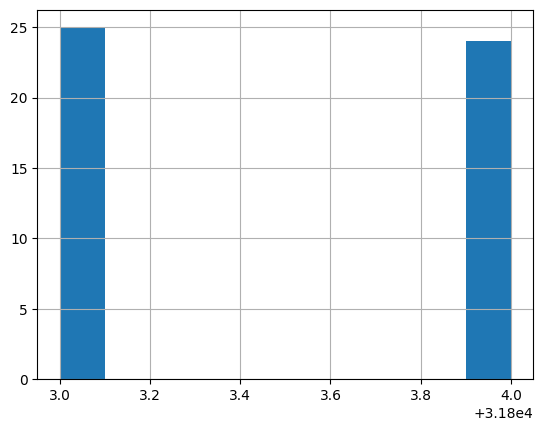

In [27]:
mask_df.sum(axis=0).hist();

Some files where a signals couldn't be found were skipped

In [28]:
skipped_files_list[:5]

[]

In [29]:
fits_df.index

DatetimeIndex(['2009-06-03 08:10:33.517454', '2009-06-03 08:10:34.977454',
               '2009-06-03 08:10:36.437454', '2009-06-03 08:10:37.897454',
               '2009-06-03 08:10:39.357454', '2009-06-03 08:10:40.817454',
               '2009-06-03 08:10:42.277454', '2009-06-03 08:10:43.737454',
               '2009-06-03 08:10:45.197454', '2009-06-03 08:10:46.657454',
               ...
               '2009-06-03 21:04:14.217454', '2009-06-03 21:04:15.677454',
               '2009-06-03 21:04:17.137454', '2009-06-03 21:04:18.597454',
               '2009-06-03 21:04:20.057454', '2009-06-03 21:04:21.517454',
               '2009-06-03 21:04:22.977454', '2009-06-03 21:04:24.437454',
               '2009-06-03 21:04:25.897454', '2009-06-03 21:04:27.357454'],
              dtype='datetime64[ns]', name='TIME', length=31805, freq=None)

Information coming from the header of each FIT file (one row per file)

In [30]:
header_df.head()

,RA,DEC,CRA,CDEC
file,,,,
P0605950101PNX000SRCTSR8012.FTZ,130.692558,-79.072054,130.693030,-79.072170
P0605950101PNX000SRCTSR802A.FTZ,131.304720,-79.043135,131.305196,-79.043253
P0605950101PNX000SRCTSR8005.FTZ,131.068342,-78.985571,131.068823,-78.985688
P0605950101PNX000SRCTSR8013.FTZ,131.248748,-78.805229,131.249248,-78.805347
P0605950101PNX000SRCTSR801E.FTZ,131.325880,-78.911909,131.326370,-78.912027


In order to get the *most promising* (meaningful) sources from some observation, its associated (*untar*ed) path is explored

In [31]:
n_sources_per_obs = 3
ranked_files_df = trapallada.xsa.util.rank_obs_files(obs_dir).iloc[:n_sources_per_obs]['full path']
ranked_files_df

30    /tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000S...
45    /tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000S...
41    /tmp/tmp_pbfcmtf/0605950101/P0605950101PNX000S...
Name: full path, dtype: object

# read_tar

High-level function to read a *tar* file into a `DataFrame`

In [32]:
tar_file_df, tar_file_headers_df, tar_mask_df = trapallada.xsa.util.read_tar(tar_file)
tar_file_df

file,P0404720301PNX000SRCTSR8001.FTZ,P0404720301PNX000SRCTSR8002.FTZ,P0404720301PNX000SRCTSR8003.FTZ,P0404720301PNX000SRCTSR8004.FTZ
data,RATE,RATE,RATE,RATE
TIME,,,,
2007-01-15 18:55:51.589320,-0.101347,-0.138722,-0.086892,-0.144360
2007-01-15 18:55:53.049320,-0.179067,-0.265774,-0.083237,-0.085022
2007-01-15 18:55:54.509320,-0.185731,1.307495,-0.108944,-0.044093
2007-01-15 18:55:55.969320,-0.194821,1.188581,-0.110012,-0.138753
2007-01-15 18:55:57.429320,-0.292804,0.000000,1.429809,-0.046342
...,...,...,...,...
2007-01-16 04:39:42.829320,0.000000,0.000000,0.000000,0.000000
2007-01-16 04:39:44.289320,0.000000,0.000000,0.000000,0.000000


In [33]:
tar_file_headers_df

,RA,DEC,CRA,CDEC
file,,,,
P0404720301PNX000SRCTSR8001.FTZ,351.257658,61.563009,351.257885,61.563287
P0404720301PNX000SRCTSR8002.FTZ,351.602702,61.718042,351.602615,61.718478
P0404720301PNX000SRCTSR8003.FTZ,351.500044,61.723238,351.499946,61.723627
P0404720301PNX000SRCTSR8004.FTZ,351.227955,61.558033,351.228191,61.558297


In [34]:
tar_mask_df.head()

,P0404720301PNX000SRCTSR8001.FTZ,P0404720301PNX000SRCTSR8002.FTZ,P0404720301PNX000SRCTSR8003.FTZ,P0404720301PNX000SRCTSR8004.FTZ
TIME,,,,
2007-01-15 18:55:51.589320,True,True,True,True
2007-01-15 18:55:53.049320,True,True,True,True
2007-01-15 18:55:54.509320,True,True,True,True
2007-01-15 18:55:55.969320,True,True,True,True
2007-01-15 18:55:57.429320,True,True,True,True


Slicing

In [35]:
window_size = 200
step = 100
slices, time_slices = trapallada.xsa.util.slice(tar_file_df, window_size=window_size, step=step)
slices.shape, time_slices.shape

((956, 1, 200), (956, 200))

First element is the 1st window for the 1st signal, second element is the 1st window for the 2nd signal, and so forth and so on. Hence,

In [36]:
(time_slices[0] == time_slices[1]).all()

np.True_

A `DataFrame` with **all** the timestamps

In [37]:
time_df = pd.DataFrame(time_slices)
time_df.head()

,0,1,2,3,4,5,6,7,8,9,...,190,191,192,193,194,195,196,197,198,199
0,2007-01-15 18:55:51.589320,2007-01-15 18:55:53.049320,2007-01-15 18:55:54.509320,2007-01-15 18:55:55.969320,2007-01-15 18:55:57.429320,2007-01-15 18:55:58.889320,2007-01-15 18:56:00.349320,2007-01-15 18:56:01.809320,2007-01-15 18:56:03.269320,2007-01-15 18:56:04.729320,...,2007-01-15 19:00:28.989320,2007-01-15 19:00:30.449320,2007-01-15 19:00:31.909320,2007-01-15 19:00:33.369320,2007-01-15 19:00:34.829320,2007-01-15 19:00:36.289320,2007-01-15 19:00:37.749320,2007-01-15 19:00:39.209320,2007-01-15 19:00:40.669320,2007-01-15 19:00:42.129320
1,2007-01-15 18:55:51.589320,2007-01-15 18:55:53.049320,2007-01-15 18:55:54.509320,2007-01-15 18:55:55.969320,2007-01-15 18:55:57.429320,2007-01-15 18:55:58.889320,2007-01-15 18:56:00.349320,2007-01-15 18:56:01.809320,2007-01-15 18:56:03.269320,2007-01-15 18:56:04.729320,...,2007-01-15 19:00:28.989320,2007-01-15 19:00:30.449320,2007-01-15 19:00:31.909320,2007-01-15 19:00:33.369320,2007-01-15 19:00:34.829320,2007-01-15 19:00:36.289320,2007-01-15 19:00:37.749320,2007-01-15 19:00:39.209320,2007-01-15 19:00:40.669320,2007-01-15 19:00:42.129320
2,2007-01-15 18:55:51.589320,2007-01-15 18:55:53.049320,2007-01-15 18:55:54.509320,2007-01-15 18:55:55.969320,2007-01-15 18:55:57.429320,2007-01-15 18:55:58.889320,2007-01-15 18:56:00.349320,2007-01-15 18:56:01.809320,2007-01-15 18:56:03.269320,2007-01-15 18:56:04.729320,...,2007-01-15 19:00:28.989320,2007-01-15 19:00:30.449320,2007-01-15 19:00:31.909320,2007-01-15 19:00:33.369320,2007-01-15 19:00:34.829320,2007-01-15 19:00:36.289320,2007-01-15 19:00:37.749320,2007-01-15 19:00:39.209320,2007-01-15 19:00:40.669320,2007-01-15 19:00:42.129320
3,2007-01-15 18:55:51.589320,2007-01-15 18:55:53.049320,2007-01-15 18:55:54.509320,2007-01-15 18:55:55.969320,2007-01-15 18:55:57.429320,2007-01-15 18:55:58.889320,2007-01-15 18:56:00.349320,2007-01-15 18:56:01.809320,2007-01-15 18:56:03.269320,2007-01-15 18:56:04.729320,...,2007-01-15 19:00:28.989320,2007-01-15 19:00:30.449320,2007-01-15 19:00:31.909320,2007-01-15 19:00:33.369320,2007-01-15 19:00:34.829320,2007-01-15 19:00:36.289320,2007-01-15 19:00:37.749320,2007-01-15 19:00:39.209320,2007-01-15 19:00:40.669320,2007-01-15 19:00:42.129320
4,2007-01-15 18:58:17.589320,2007-01-15 18:58:19.049320,2007-01-15 18:58:20.509320,2007-01-15 18:58:21.969320,2007-01-15 18:58:23.429320,2007-01-15 18:58:24.889320,2007-01-15 18:58:26.349320,2007-01-15 18:58:27.809320,2007-01-15 18:58:29.269320,2007-01-15 18:58:30.729320,...,2007-01-15 19:02:54.989320,2007-01-15 19:02:56.449320,2007-01-15 19:02:57.909320,2007-01-15 19:02:59.369320,2007-01-15 19:03:00.829320,2007-01-15 19:03:02.289320,2007-01-15 19:03:03.749320,2007-01-15 19:03:05.209320,2007-01-15 19:03:06.669320,2007-01-15 19:03:08.129320


The durations can be easily obtained...

In [38]:
durations = time_df.iloc[:, -1] - time_df.iloc[:, 0]
durations.head()

0   0 days 00:04:50.540000
1   0 days 00:04:50.540000
2   0 days 00:04:50.540000
3   0 days 00:04:50.540000
4   0 days 00:04:50.540000
dtype: timedelta64[ns]

...as well as the periods

In [39]:
periods = time_df.iloc[:, 1] - time_df.iloc[:, 0]
periods.head()

0   0 days 00:00:01.460000
1   0 days 00:00:01.460000
2   0 days 00:00:01.460000
3   0 days 00:00:01.460000
4   0 days 00:00:01.460000
dtype: timedelta64[ns]

## `RATE`'s vs mask

In this observation the *mask* indicates the values are **not** valid despite the fact that there is nothing wrong with any of the corresponding *signal*s.

In [40]:
obs_mask_vs_nans = '0200510101'
tar_file = trapallada.xsa.access.download_obs(obs_mask_vs_nans, output_directory=tmp_dir_root)
tar_file_df, tar_file_headers_df, tar_mask_df = trapallada.xsa.util.read_tar(tar_file, signals_to_extract=trapallada.xsa.util.rates_columns)
print(tar_file_df.shape)
tar_file_df.head()

INFO: https://nxsa.esac.esa.int/nxsa-sl/servlet/data-action-aio?obsno=0200510101&level=PPS&instname=PN [astroquery.esa.xmm_newton.core]
INFO: Wrote https://nxsa.esac.esa.int/nxsa-sl/servlet/data-action-aio?obsno=0200510101&level=PPS&instname=PN to /tmp/tmp_pbfcmtf/0200510101.tar [astroquery.esa.xmm_newton.core]


trapallada.xsa.util - WARNING - Time stamps for file "0200510101/P0200510101PNX000SRCTSR8004.FTZ" don't match those for "0200510101/P0200510101PNX000SRCTSR8001.FTZ" (the first file, taken as reference), skipping...


(14419, 15)


file                       P0200510101PNX000SRCTSR8001.FTZ                  \
data                                                 RATE1 RATE2     RATE3   
TIME                                                                         
2005-01-04 22:00:22.010634                        0.000000   0.0  0.000000   
2005-01-04 22:00:23.470634                        0.000000   0.0  0.000000   
2005-01-04 22:00:24.930634                        0.000000   0.0  0.000000   
2005-01-04 22:00:26.390634                        0.777559   0.0  0.000000   
2005-01-04 22:00:27.850634                        0.000000   0.0  0.768235   

file                                       P0200510101PNX000SRCTSR8002.FTZ  \
data                       RATE4     RATE5                           RATE1   
TIME                                                                         
2005-01-04 22:00:22.010634   0.0  0.000000                             0.0   
2005-01-04 22:00:23.470634   0.0  0.764513                             0.0   
2005-01-04 22:00:24.930634   0.0  0.000000                             0.0   
2005-01-04 22:00:26.390634   0.0  0.000000                             0.0   
2005-01-04 22:00:27.850634   0.0  0.000000                             0.0   

file                                                \
data                       RATE2 RATE3 RATE4 RATE5   
TIME                                                 
2005-01-04 22:00:22.010634   0.0   0.0   0.0   0.0   
2005-01-04 22:00:23.470634   0.0   0.0   0.0   0.0   
2005-01-04 22:00:24.930634   0.0   0.0   0.0   0.0   
2005-01-04 22:00:26.390634   0.0   0.0   0.0   0.0   
2005-01-04 22:00:27.850634   0.0   0.0   0.0   0.0   

file                       P0200510101PNX000SRCTSR8003.FTZ                    \
data                                                 RATE1 RATE2 RATE3 RATE4   
TIME                                                                           
2005-01-04 22:00:22.010634                             0.0   0.0   0.0   0.0   
2005-01-04 22:00:23.470634                             0.0   0.0   0.0   0.0   
2005-01-04 22:00:24.930634                             0.0   0.0   0.0   0.0   
2005-01-04 22:00:26.390634                             0.0   0.0   0.0   0.0   
2005-01-04 22:00:27.850634                             0.0   0.0   0.0   0.0   

file                                  
data                           RATE5  
TIME                                  
2005-01-04 22:00:22.010634  0.000000  
2005-01-04 22:00:23.470634  0.000000  
2005-01-04 22:00:24.930634  0.818611  
2005-01-04 22:00:26.390634  0.000000  
2005-01-04 22:00:27.850634  0.000000

For every signal, it is assessed whether there is any *rate* column (`RATE1`, `RATE2`,...) having either an $\infty$ or a `NaN`. Replacing
- `NaN`s and
- $-\infty$'s

with $\infty$'s (`fillna`) is a workaround for the fact that `mean` applied on a *grouped* `DataFarme` treats `NaN` values as 0s (the former being lost in the process). `any_bad_rate` being `True` at some time instant for a signal means the corresponding row is not *valid* (there is something wrong with one or more `RATE`* columns).

In [41]:
any_bad_rate = np.isinf(
    tar_file_df.replace(-np.inf, np.inf).
    fillna(np.inf).
    loc[:, pd.IndexSlice[:, trapallada.xsa.util.rates_columns]].T.
    groupby(level=0).mean()).T
any_bad_rate.tail()

file,P0200510101PNX000SRCTSR8001.FTZ,P0200510101PNX000SRCTSR8002.FTZ,P0200510101PNX000SRCTSR8003.FTZ
TIME,,,
2005-01-05 06:15:48.331426,True,True,True
2005-01-05 06:15:49.791426,True,True,True
2005-01-05 06:15:51.251426,True,True,True
2005-01-05 06:15:52.711426,True,True,True
2005-01-05 06:15:54.171426,True,True,True


Do the above variable and the *mask* agree?

In [42]:
# (any_bad_rate == ~tar_mask_df).all().all()
rates_and_mask_agree = (~any_bad_rate == tar_mask_df)
rates_and_mask_agree.head()

file,P0200510101PNX000SRCTSR8001.FTZ,P0200510101PNX000SRCTSR8002.FTZ,P0200510101PNX000SRCTSR8003.FTZ
TIME,,,
2005-01-04 22:00:22.010634,True,True,True
2005-01-04 22:00:23.470634,True,True,True
2005-01-04 22:00:24.930634,True,True,True
2005-01-04 22:00:26.390634,True,True,True
2005-01-04 22:00:27.850634,True,True,True


Do they disagree at some point?

In [43]:
(~rates_and_mask_agree).any().any()

np.True_

Where do they disagree?

In [44]:
not_matching = (~(any_bad_rate == ~tar_mask_df)).stack()
mismatch = not_matching[not_matching==True]
mismatch

TIME                        file                           
2005-01-05 00:52:40.991426  P0200510101PNX000SRCTSR8001.FTZ    True
                            P0200510101PNX000SRCTSR8002.FTZ    True
                            P0200510101PNX000SRCTSR8003.FTZ    True
2005-01-05 00:52:42.451426  P0200510101PNX000SRCTSR8001.FTZ    True
                            P0200510101PNX000SRCTSR8002.FTZ    True
                                                               ... 
2005-01-05 06:15:14.751426  P0200510101PNX000SRCTSR8002.FTZ    True
                            P0200510101PNX000SRCTSR8003.FTZ    True
2005-01-05 06:15:16.211426  P0200510101PNX000SRCTSR8001.FTZ    True
                            P0200510101PNX000SRCTSR8002.FTZ    True
                            P0200510101PNX000SRCTSR8003.FTZ    True
Length: 28205, dtype: bool

For instance, for the first time instant above (notice the *mask* is `True` when the value is valid)

In [45]:
display(tar_file_df.loc[mismatch.index[0][0]])
tar_mask_df.loc[mismatch.index[0][0]]

file                             data 
P0200510101PNX000SRCTSR8001.FTZ  RATE1    0.0
                                 RATE2    0.0
                                 RATE3    0.0
                                 RATE4    0.0
                                 RATE5    0.0
P0200510101PNX000SRCTSR8002.FTZ  RATE1    0.0
                                 RATE2    0.0
                                 RATE3    0.0
                                 RATE4    0.0
                                 RATE5    0.0
P0200510101PNX000SRCTSR8003.FTZ  RATE1    0.0
                                 RATE2    0.0
                                 RATE3    0.0
                                 RATE4    0.0
                                 RATE5    0.0
Name: 2005-01-05 00:52:40.991426, dtype: float32

P0200510101PNX000SRCTSR8001.FTZ    False
P0200510101PNX000SRCTSR8002.FTZ    False
P0200510101PNX000SRCTSR8003.FTZ    False
Name: 2005-01-05 00:52:40.991426, dtype: bool

## Infinities

In [46]:
obs_infty = '0690744401'
tar_file = trapallada.xsa.access.download_obs(obs_infty, output_directory=tmp_dir_root)
tar_file_df, tar_file_headers_df, tar_mask_df = trapallada.xsa.util.read_tar(tar_file, signals_to_extract=trapallada.xsa.util.rates_columns)
print(tar_file_df.shape)
tar_file_df.head()

INFO: https://nxsa.esac.esa.int/nxsa-sl/servlet/data-action-aio?obsno=0690744401&level=PPS&instname=PN [astroquery.esa.xmm_newton.core]
INFO: Wrote https://nxsa.esac.esa.int/nxsa-sl/servlet/data-action-aio?obsno=0690744401&level=PPS&instname=PN to /tmp/tmp_pbfcmtf/0690744401.tar [astroquery.esa.xmm_newton.core]
(29344, 20)


file                       P0690744401PNX000SRCTSR8001.FTZ            \
data                                                 RATE1     RATE2   
TIME                                                                   
2012-10-23 18:27:18.730736                        0.000000  0.881468   
2012-10-23 18:27:20.190736                        0.000000 -0.122561   
2012-10-23 18:27:21.650736                        0.000000  0.000000   
2012-10-23 18:27:23.110736                       -0.117932  0.000000   
2012-10-23 18:27:24.570736                        0.000000  0.000000   

file                                                      \
data                           RATE3     RATE4     RATE5   
TIME                                                       
2012-10-23 18:27:18.730736 -0.123109 -0.369326  0.901176   
2012-10-23 18:27:20.190736  0.877549 -0.367684  0.264743   
2012-10-23 18:27:21.650736 -0.119268  0.496164 -0.954143   
2012-10-23 18:27:23.110736  0.000000  0.844404  0.018879   
2012-10-23 18:27:24.570736  0.723737  0.606249 -0.469953   

file                       P0690744401PNX000SRCTSR8002.FTZ            \
data                                                 RATE1     RATE2   
TIME                                                                   
2012-10-23 18:27:18.730736                        1.762060  0.881030   
2012-10-23 18:27:20.190736                        0.857261  1.714522   
2012-10-23 18:27:21.650736                        0.000000  0.000000   
2012-10-23 18:27:23.110736                        0.851897  0.000000   
2012-10-23 18:27:24.570736                        0.000000  0.000000   

file                                                      \
data                           RATE3     RATE4     RATE5   
TIME                                                       
2012-10-23 18:27:18.730736  0.000000  0.881030  1.187172   
2012-10-23 18:27:20.190736  0.000000  0.000000 -2.499010   
2012-10-23 18:27:21.650736  0.294554  0.847681  1.142235   
2012-10-23 18:27:23.110736 -0.259859  0.000000 -0.815738   
2012-10-23 18:27:24.570736  0.849164 -1.108190  1.439302   

file                       P0690744401PNX000SRCTSR8003.FTZ            \
data                                                 RATE1     RATE2   
TIME                                                                   
2012-10-23 18:27:18.730736                             0.0 -0.127532   
2012-10-23 18:27:20.190736                             0.0 -0.127042   
2012-10-23 18:27:21.650736                             0.0  0.000000   
2012-10-23 18:27:23.110736                             0.0  0.599918   
2012-10-23 18:27:24.570736                             0.0 -0.121854   

file                                                      \
data                           RATE3     RATE4     RATE5   
TIME                                                       
2012-10-23 18:27:18.730736  0.000000  0.000000  0.753403   
2012-10-23 18:27:20.190736  0.000000  0.877549  0.496424   
2012-10-23 18:27:21.650736  0.000000  0.483084  0.112201   
2012-10-23 18:27:23.110736  0.000000 -0.122243  1.444322   
2012-10-23 18:27:24.570736 -0.121854 -0.243707  0.598005   

file                       P0690744401PNX000SRCTSR8004.FTZ            \
data                                                 RATE1     RATE2   
TIME                                                                   
2012-10-23 18:27:18.730736                             0.0 -0.128077   
2012-10-23 18:27:20.190736                             0.0  0.000000   
2012-10-23 18:27:21.650736                             0.0  0.853968   
2012-10-23 18:27:23.110736                             0.0 -0.245531   
2012-10-23 18:27:24.570736                             0.0 -0.122374   

file                                                      
data                           RATE3     RATE4     RATE5  
TIME                                                      
2012-10-23 18:27:18.730736  0.000000  0.000000 -0.128077  
2012-10-23 18

In [47]:
# np.isinf(tar_file_df['P0690744401PNX000SRCTSR8002.FTZ']).sum()
np.isinf(tar_file_df).sum().sum()

np.int64(1)

In [48]:
np.isinf(tar_file_df)

file                       P0690744401PNX000SRCTSR8001.FTZ                \
data                                                 RATE1  RATE2  RATE3   
TIME                                                                       
2012-10-23 18:27:18.730736                           False  False  False   
2012-10-23 18:27:20.190736                           False  False  False   
2012-10-23 18:27:21.650736                           False  False  False   
2012-10-23 18:27:23.110736                           False  False  False   
2012-10-23 18:27:24.570736                           False  False  False   
...                                                    ...    ...    ...   
2012-10-24 06:21:13.670736                           False  False  False   
2012-10-24 06:21:15.130736                           False  False  False   
2012-10-24 06:21:16.590736                           False  False  False   
2012-10-24 06:21:18.050736                           False  False  False   
2012-10-24 06:21:19.510736                           False  False  False   

file                                     P0690744401PNX000SRCTSR8002.FTZ  \
data                        RATE4  RATE5                           RATE1   
TIME                                                                       
2012-10-23 18:27:18.730736  False  False                           False   
2012-10-23 18:27:20.190736  False  False                           False   
2012-10-23 18:27:21.650736  False  False                           False   
2012-10-23 18:27:23.110736  False  False                           False   
2012-10-23 18:27:24.570736  False  False                           False   
...                           ...    ...                             ...   
2012-10-24 06:21:13.670736  False  False                           False   
2012-10-24 06:21:15.130736  False  False                           False   
2012-10-24 06:21:16.590736  False  False                           False   
2012-10-24 06:21:18.050736  False  False                           False   
2012-10-24 06:21:19.510736  False  False                           False   

file                                                    \
data                        RATE2  RATE3  RATE4  RATE5   
TIME                                                     
2012-10-23 18:27:18.730736  False  False  False  False   
2012-10-23 18:27:20.190736  False  False  False  False   
2012-10-23 18:27:21.650736  False  False  False  False   
2012-10-23 18:27:23.110736  False  False  False  False   
2012-10-23 18:27:24.570736  False  False  False  False   
...                           ...    ...    ...    ...   
2012-10-24 06:21:13.670736  False  False  False  False   
2012-10-24 06:21:15.130736  False  False  False  False   
2012-10-24 06:21:16.590736  False  False  False  False   
2012-10-24 06:21:18.050736  False  False  False  False   
2012-10-24 06:21:19.510736  False  False  False  False   

file                       P0690744401PNX000SRCTSR8003.FTZ                \
data                                                 RATE1  RATE2  RATE3   
TIME                                                                       
2012-10-23 18:27:18.730736                           False  False  False   
2012-10-23 18:27:20.190736                           False  False  False   
2012-10-23 18:27:21.650736                           False  False  False   
2012-10-23 18:27:23.110736                           False  False  False   
2012-10-23 18:27:24.570736                           False  False  False   
...                                                    ...    ...    ...   
2012-10-24 06:21:13.670736                           False  False  False   
2012-10-24 06:21:15.130736                           False  False  False   
2012-10-24 06:21:16.590736                           False  False  False   
2012-10-24 06:21:18.050736                           False  False  False   
2012-10-24 06:21:19.510736                           False  False  Fa

Signals have *any* infinity in *any* of the `RATE`* columns

In [49]:
ftz_has_inftys = np.isinf(tar_file_df).loc[:, pd.IndexSlice[:, trapallada.xsa.util.rates_columns]].T.groupby(level=0).any().T.any(axis=0)
ftz_has_inftys

file
P0690744401PNX000SRCTSR8001.FTZ     True
P0690744401PNX000SRCTSR8002.FTZ    False
P0690744401PNX000SRCTSR8003.FTZ    False
P0690744401PNX000SRCTSR8004.FTZ    False
dtype: bool

Signals to be dismissed

In [50]:
ftzs_to_be_dismissed = ftz_has_inftys.index[ftz_has_inftys].tolist()
ftzs_to_be_dismissed

['P0690744401PNX000SRCTSR8001.FTZ']

In [51]:
# tar_file_df.drop(ftzs_to_be_dismissed, axis=1)
tar_file_headers_df.drop(ftzs_to_be_dismissed, axis=0)
# tar_mask_df.drop(ftzs_to_be_dismissed, axis=1)

,RA,DEC,CRA,CDEC
file,,,,
P0690744401PNX000SRCTSR8002.FTZ,84.644581,-68.885414,84.644243,-68.885177
P0690744401PNX000SRCTSR8003.FTZ,84.677448,-69.092757,84.677752,-69.092507
P0690744401PNX000SRCTSR8004.FTZ,84.682811,-69.101702,84.683143,-69.101450


Which column of the specific signal

In [52]:
fit_file_infty = ftzs_to_be_dismissed[0]
np.isinf(tar_file_df[fit_file_infty]).any(axis=0)

data
RATE1    False
RATE2    False
RATE3     True
RATE4    False
RATE5    False
dtype: bool

However, when looking at the (*overall*) `RATE` column, there are no $\infty$'s

In [53]:
rate_df, *_ = trapallada.xsa.util.read_tar(tar_file, signals_to_extract=['RATE'])
np.isinf(rate_df[fit_file_infty]).any()

data
RATE    False
dtype: bool

# `tars_to_array`

The *tar* files downloaded above (into a temporary directory)...

In [54]:
list(tmp_dir_root.glob('*.tar'))

[PosixPath('/tmp/tmp_pbfcmtf/0690744401.tar'),
 PosixPath('/tmp/tmp_pbfcmtf/0200510101.tar'),
 PosixPath('/tmp/tmp_pbfcmtf/0605950101.tar'),
 PosixPath('/tmp/tmp_pbfcmtf/0404720301.tar')]

...are turned into an `Array` (and a companion `DataFrame` with metadata). Some *pre*-processing is applied:

- signals are **normalized** (zero mean, unit standard deviation)

In [55]:
signals, metadata_df, headers_df, full_signals, masks  = trapallada.xsa.util.tars_to_array(tmp_dir_root.glob('*.tar'))
signals.shape, metadata_df.shape, headers_df.shape, masks.shape

trapallada.xsa.util - INFO - Requested a window size of, effectively, duration 18396.0 seconds (period is 91.98 seconds, step is 4599.0 seconds)
trapallada.xsa.util - WARNING - Time stamps for file "0200510101/P0200510101PNX000SRCTSR8004.FTZ" don't match those for "0200510101/P0200510101PNX000SRCTSR8001.FTZ" (the first file, taken as reference), skipping...


((86, 1, 200), (86, 4), (15, 4), (86, 200))

Columns in the metadata `DataFrame`

In [56]:
metadata_df.columns

Index(['start', 'end', 'tar file', 'source'], dtype='object')

Metadata for the headers (notice that every FIT file is *sliced* into multiple signals)

In [57]:
headers_df

RA        DEC  \
tar file       source                                                   
0690744401.tar P0690744401PNX000SRCTSR8001.FTZ   84.446211 -69.171871   
               P0690744401PNX000SRCTSR8002.FTZ   84.644581 -68.885414   
               P0690744401PNX000SRCTSR8003.FTZ   84.677448 -69.092757   
               P0690744401PNX000SRCTSR8004.FTZ   84.682811 -69.101702   
0200510101.tar P0200510101PNX000SRCTSR8001.FTZ  186.508251  31.201402   
               P0200510101PNX000SRCTSR8002.FTZ  186.706778  31.293429   
               P0200510101PNX000SRCTSR8003.FTZ  186.612834  31.223841   
0605950101.tar P0605950101PNX000SRCTSR8001.FTZ  131.755916 -78.993045   
               P0605950101PNX000SRCTSR8002.FTZ  130.779291 -79.081070   
               P0605950101PNX000SRCTSR8003.FTZ  130.598155 -79.067407   
               P0605950101PNX000SRCTSR8004.FTZ  130.799788 -79.070072   
0404720301.tar P0404720301PNX000SRCTSR8001.FTZ  351.257658  61.563009   
               P0404720301PNX000SRCTSR8002.FTZ  351.602702  61.718042   
               P0404720301PNX000SRCTSR8003.FTZ  351.500044  61.723238   
               P0404720301PNX000SRCTSR8004.FTZ  351.227955  61.558033   

                                                       CRA       CDEC  
tar file       source                                                  
0690744401.tar P0690744401PNX000SRCTSR8001.FTZ   84.446763 -69.171713  
               P0690744401PNX000SRCTSR8002.FTZ   84.644243 -68.885177  
               P0690744401PNX000SRCTSR8003.FTZ   84.677752 -69.092507  
               P0690744401PNX000SRCTSR8004.FTZ   84.683143 -69.101450  
0200510101.tar P0200510101PNX000SRCTSR8001.FTZ  186.507834  31.201636  
               P0200510101PNX000SRCTSR8002.FTZ  186.706524  31.293406  
               P0200510101PNX000SRCTSR8003.FTZ  186.612457  31.223939  
0605950101.tar P0605950101PNX000SRCTSR8001.FTZ  131.756397 -78.993165  
               P0605950101PNX000SRCTSR8002.FTZ  130.779762 -79.081186  
               P0605950101PNX000SRCTSR8003.FTZ  130.598627 -79.067521  
               P0605950101PNX000SRCTSR8004.FTZ  130.800260 -79.070188  
0404720301.tar P0404720301PNX000SRCTSR8001.FTZ  351.257885  61.563287  
               P0404720301PNX000SRCTSR8002.FTZ  351.602615  61.718478  
               P0404720301PNX000SRCTSR8003.FTZ  351.499946  61.723627  
               P0404720301PNX000SRCTSR8004.FTZ  351.228191  61.558297

Durations:

In [58]:
(metadata_df['end'] - metadata_df['start']).head()

0   0 days 05:05:04.020000
1   0 days 05:05:04.020000
2   0 days 05:05:04.020000
3   0 days 05:05:04.020000
4   0 days 05:05:04.020000
dtype: timedelta64[ns]

For one particular relevant observation

In [59]:
# relevant_source = metadata_df['source'] == 'P0605950101PNS003SRCTSR8001.FTZ'
relevant_source = metadata_df['source'] == fit_file
metadata_df[relevant_source]

,start,end,tar file,source
34,2009-06-03 08:12:05.497454,2009-06-03 13:17:09.517454,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ
38,2009-06-03 09:28:44.497454,2009-06-03 14:33:48.517454,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ
42,2009-06-03 10:45:23.497454,2009-06-03 15:50:27.517454,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ
46,2009-06-03 12:02:02.497454,2009-06-03 17:07:06.517454,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ
50,2009-06-03 13:18:41.497454,2009-06-03 18:23:45.517454,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ
54,2009-06-03 14:35:20.497454,2009-06-03 19:40:24.517454,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ
58,2009-06-03 15:51:59.497454,2009-06-03 20:57:03.517454,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ
62,2009-06-03 15:58:07.417454,2009-06-03 21:03:11.437454,0605950101.tar,P0605950101PNX000SRCTSR8001.FTZ


Plot

In [60]:
trapallada.plot.signals_array(signals[relevant_source, 0, :][-1:])

The data from the header

In [61]:
# headers_df.xs('P0605950101PNS003SRCTSR8001.FTZ', level='source')
headers_df.xs(fit_file, level='source')

,RA,DEC,CRA,CDEC
tar file,,,,
0605950101.tar,131.755916,-78.993045,131.756397,-78.993165


The full signals are available through a dictionary whose *key*s are the different *tar* files

In [62]:
full_signals.keys()

dict_keys(['0690744401.tar', '0200510101.tar', '0605950101.tar', '0404720301.tar'])

Each one is associated with 2 `DataFrame`s

In [63]:
full_signals_df, full_signals_mask_df = full_signals[next(iter(full_signals.keys()))]
display(full_signals_df)
display(Markdown('---'))
display(full_signals_mask_df)

file,P0690744401PNX000SRCTSR8001.FTZ,P0690744401PNX000SRCTSR8002.FTZ,P0690744401PNX000SRCTSR8003.FTZ,P0690744401PNX000SRCTSR8004.FTZ
data,RATE,RATE,RATE,RATE
TIME,,,,
2012-10-23 18:28:50.710736,0.309110,1.312317,1.255571,1.752315
2012-10-23 18:30:22.690736,2.528255,0.122930,0.059534,9.343248
2012-10-23 18:31:54.670736,4.202031,1.716370,2.677958,1.678907
2012-10-23 18:33:26.650736,-1.889188,5.405970,5.109555,2.719893
2012-10-23 18:34:58.630736,-0.076286,2.260679,1.603171,0.255804
...,...,...,...,...
2012-10-24 06:14:01.510736,0.970440,-0.236672,-0.412811,-0.780952
2012-10-24 06:15:33.490736,-0.123081,-0.268372,0.081035,-0.509623


---

file,P0690744401PNX000SRCTSR8001.FTZ,P0690744401PNX000SRCTSR8002.FTZ,P0690744401PNX000SRCTSR8003.FTZ,P0690744401PNX000SRCTSR8004.FTZ
data,OK,OK,OK,OK
TIME,,,,
2012-10-23 18:28:50.710736,False,True,False,False
2012-10-23 18:30:22.690736,False,False,False,False
2012-10-23 18:31:54.670736,False,False,False,False
2012-10-23 18:33:26.650736,False,False,False,False
2012-10-23 18:34:58.630736,False,True,False,False
...,...,...,...,...
2012-10-24 06:14:01.510736,True,True,True,True
2012-10-24 06:15:33.490736,True,True,True,True


How many wrong values for every signal

In [64]:
(~full_signals_mask_df).sum(axis=0)

file                             data
P0690744401PNX000SRCTSR8001.FTZ  OK      55
P0690744401PNX000SRCTSR8002.FTZ  OK      23
P0690744401PNX000SRCTSR8003.FTZ  OK      55
P0690744401PNX000SRCTSR8004.FTZ  OK      55
dtype: int64

The lenghts of every full signal

In [65]:
lengths = [len(dfs[0]) for tar_file, dfs in full_signals.items()]
lengths

[465, 228, 504, 380]

Signals are slices of those

In [66]:
signals.shape

(86, 1, 200)

In [67]:
# signals, metadata_df, headers_df, full_signals, masks  = trapallada.xsa.util.tars_to_array(tmp_dir_root.glob('*.tar'), bin_size=0, window_size=225*63, step=10*63)

The directory with **all** the data (~80 GBs)

In [68]:
# full_data_dir = pathlib.Path(os.environ['MY_DATA_DIR']) / 'trapallada'
full_data_dir = pathlib.Path(os.environ['MY_DATA_DIR']) / 'trapallada2'

In [69]:
# arguments = [full_data_dir.as_posix(), 'foo', 'fa', '-b', '63', '-w', '225', '-s', '10', '-M', '4', '-m', '0', '-c', '0.02', '-g', '0.2']
# trapallada.xsa.util.cl_tars_to_array(arguments)

In [70]:
# signals, metadata_df, headers_df, full_signals, masks  = trapallada.xsa.util.tars_to_array(full_data_dir.glob('*.tar'), 63, 225, 10, 4, 0, 0.02, 0.2)

# cl_tars_to_array

In [74]:
arguments + [tmp_output_dir, 'sample'] + ['--signals-to-extract'] + trapallada.xsa.util.rates_columns

['/tmp/tmp_pbfcmtf',
 '/tmp/tmp_y3tyo6u',
 'sample',
 '--signals-to-extract',
 'RATE1',
 'RATE2',
 'RATE3',
 'RATE4',
 'RATE5']

In [ ]:
arguments = [tmp_dir_root.as_posix()]
with tempfile.TemporaryDirectory(delete=False) as tmp_output_dir:
    trapallada.xsa.util.cl_tars_to_array(arguments + [tmp_output_dir, 'sample'] + ['--signals-to-extract'] + trapallada.xsa.util.rates_columns)
tmp_output_dir

trapallada.xsa.util - WARNING - signals ['P0690744401PNX000SRCTSR8001.FTZ'] in "/tmp/tmp_pbfcmtf/0690744401.tar" has +/- infinity values, skipping...
trapallada.xsa.util - INFO - Requested a window size of, effectively, duration 18396.0 seconds (period is 91.98 seconds, step is 4599.0 seconds)
trapallada.xsa.util - WARNING - Time stamps for file "0200510101/P0200510101PNX000SRCTSR8004.FTZ" don't match those for "0200510101/P0200510101PNX000SRCTSR8001.FTZ" (the first file, taken as reference), skipping...
trapallada.xsa.util - WARNING - signals ['P0200510101PNX000SRCTSR8001.FTZ', 'P0200510101PNX000SRCTSR8002.FTZ', 'P0200510101PNX000SRCTSR8003.FTZ'] in "/tmp/tmp_pbfcmtf/0200510101.tar" has +/- infinity values, skipping...
trapallada.xsa.util - WARNING - every signal has power below 0.0 in "/tmp/tmp_pbfcmtf/0200510101.tar", skipping...
trapallada.xsa.util - INFO - 73 signals of length 200 samples (18304.02 seconds)
trapallada.xsa.util - INFO - Parameters are {'bin_size': 63,
 'max_n_sourc

'/tmp/tmp_y3tyo6u'

# get_full_signal

Here, we are extracting `RATE1` in particular.

In [72]:
# trapallada.xsa.util.get_full_signal('0404720301/P0404720301PNS003SRCTSR8001', pathlib.Path(tmp_output_dir) / 'sample' / 'full_signals')
trapallada.xsa.util.get_full_signal('0404720301/P0404720301PNX000SRCTSR8001', pathlib.Path(tmp_output_dir) / 'sample' / 'full_signals', column='RATE1')

(TIME
 2007-01-15 18:57:23.569320   -0.294014
 2007-01-15 18:58:55.549320   -0.294014
 2007-01-15 19:00:27.529320   -0.294014
 2007-01-15 19:01:59.509320    7.610776
 2007-01-15 19:03:31.489320   -0.294014
                                 ...   
 2007-01-16 04:32:16.069320   -0.294014
 2007-01-16 04:33:48.049320   -0.294014
 2007-01-16 04:35:20.029320    3.063929
 2007-01-16 04:36:52.009320    2.544479
 2007-01-16 04:38:23.989320    2.524517
 Name: (P0404720301PNX000SRCTSR8001.FTZ, RATE1), Length: 380, dtype: float64,
 TIME
 2007-01-15 18:57:23.569320    True
 2007-01-15 18:58:55.549320    True
 2007-01-15 19:00:27.529320    True
 2007-01-15 19:01:59.509320    True
 2007-01-15 19:03:31.489320    True
                               ... 
 2007-01-16 04:32:16.069320    True
 2007-01-16 04:33:48.049320    True
 2007-01-16 04:35:20.029320    True
 2007-01-16 04:36:52.009320    True
 2007-01-16 04:38:23.989320    True
 Name: (P0404720301PNX000SRCTSR8001.FTZ, OK), Length: 380, dtype: bool)

# get_full_signals

In [ ]:
trapallada.xsa.util.get_full_signals('0404720301/P0404720301PNX000SRCTSR8001', pathlib.Path(tmp_output_dir) / 'sample' / 'full_signals')

(data                           RATE1     RATE2     RATE3     RATE4     RATE5
 TIME                                                                        
 2007-01-15 18:57:23.569320 -0.294014 -0.566235  2.378593  1.883989  4.425532
 2007-01-15 18:58:55.549320 -0.294014 -0.566235 -0.770621  3.502937  3.082441
 2007-01-15 19:00:27.529320 -0.294014  6.079143  2.344473  2.161434  8.116025
 2007-01-15 19:01:59.509320  7.610776  2.797909 -0.770621 -0.681765  4.679399
 2007-01-15 19:03:31.489320 -0.294014 -0.566235  0.438256  2.052385  6.679115
 ...                              ...       ...       ...       ...       ...
 2007-01-16 04:32:16.069320 -0.294014 -0.566235  0.281846 -0.681765 -0.499699
 2007-01-16 04:33:48.049320 -0.294014 -0.566235  0.624344 -0.681765  0.850411
 2007-01-16 04:35:20.029320  3.063929  1.273656 -0.770621 -0.681765  0.176529
 2007-01-16 04:36:52.009320  2.544479 -0.566235  1.312490 -0.681765  0.167055
 2007-01-16 04:38:23.989320  2.524517 -0.566235 -0.770621  0.431